In [18]:
import os
import sys
import joblib

import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.constants import Configs
from utils.loso_models.zscore_detector import ZScoreDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.metrics import show_feature_extraction_metrics
from utils.helper_functions import calculate_trash_percentage
from utils.plotting import plot_movement_data
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Pick'
ALGORITHM_NAME = 'ZScore'
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

In [19]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [20]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 13


,sub,repID,movID,movLabel
0,4,1,3,Pick
1,5,2,5,Pick
2,5,5,3,Pick
3,8,1,1,Pick
4,9,1,3,Pick


### Load Features from Csv

In [21]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()

assert not np.isnan(X_features).any(), "NaN in features"

In [22]:
total_trials_unique = features_df.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)
total_samples = len(features_df)
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100

print(f"--- Preparation (Feature-Based) ---")
print(f"Total samples analyzed ({TARGET_MOVEMENT}): {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate in CSV (sub + repID): {percentagem_conhecida:.2f}%")

--- Preparation (Feature-Based) ---
Total samples analyzed (Pick): 380
Total unique repetitions analyzed (Pick): 95
Minimum confirmed outlier rate in CSV (sub + repID): 3.42%


### Normality Test

--- Shapiro-Wilk Test Results ---
Feature         | P-Value      | Conclusion
---------------------------------------------
duration        | 0.000001 | Not Normal
range_x         | 0.000216 | Not Normal
range_y         | 0.000000 | Not Normal
range_z         | 0.000000 | Not Normal
path_length     | 0.000000 | Not Normal
path_ratio      | 0.000000 | Not Normal
mean_vel        | 0.549257 | Normal
max_vel         | 0.007576 | Not Normal
time_to_peak_vel | 0.000000 | Not Normal
mean_to_peak_vel_ratio | 0.310281 | Normal
vel_skewness    | 0.537392 | Normal
n_velocity_peaks | 0.000000 | Not Normal
mean_acc        | 0.000002 | Not Normal
max_acc         | 0.000000 | Not Normal
max_jerk        | 0.000000 | Not Normal
ldlj            | 0.000000 | Not Normal
sparc           | 0.000000 | Not Normal
total_curvature | 0.000000 | Not Normal
total_torsion   | 0.031998 | Not Normal


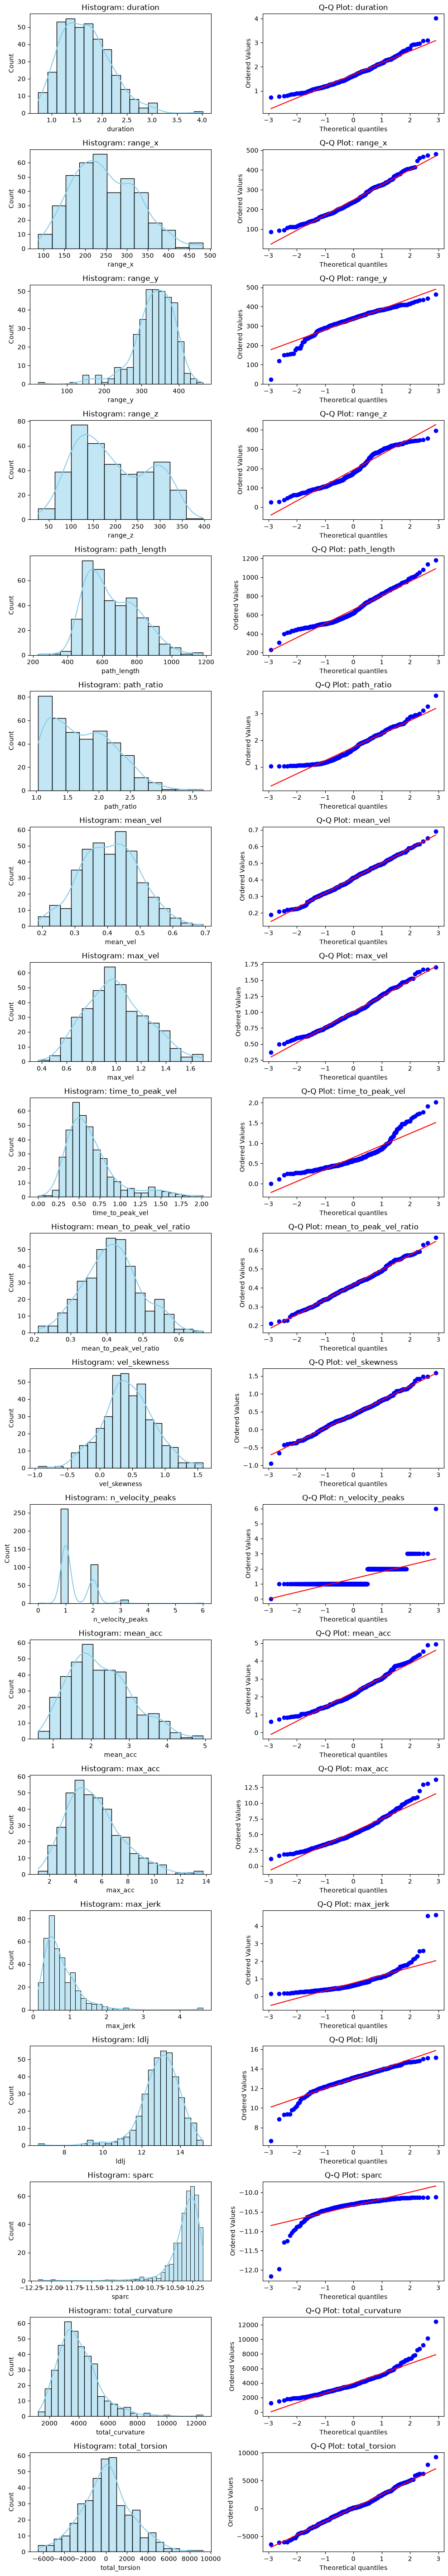

In [23]:
fig, axes = plt.subplots(len(Configs.FEATURE_COLS), 2, figsize=(10, 3 * len(Configs.FEATURE_COLS)))

print("--- Shapiro-Wilk Test Results ---")
print(f"{'Feature':<15} | {'P-Value':<12} | {'Conclusion'}")
print("-" * 45)

for i, col in enumerate(Configs.FEATURE_COLS):
    data = features_df[col].dropna() # Remove NaNs for safety
    
    # Statistical Test (Shapiro-Wilk)
    # Note: For N > 5000, Shapiro becomes too sensitive. 
    # If you have a lot of data, use stats.normaltest() (D'Agostino's K^2)
    stat, p_value = stats.shapiro(data)
    
    is_normal = p_value > 0.05
    conclusion = "Normal" if is_normal else "Not Normal"
    
    print(f"{col:<15} | {p_value:.6f} | {conclusion}")

    # Left: Histogram + KDE
    sns.histplot(data, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Histogram: {col}')
    
    # Right: Q-Q Plot 
    stats.probplot(data, dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'Q-Q Plot: {col}')

plt.tight_layout()
plt.show()

## Z-Score Feature Extraction

This is not a machine learning algorithm, so it does not have any hyperparameters to grid search. Maybe the LOSO pipeline is not necessary.

In [24]:
def modified_zscore(series):
    """
    Como aparentemente os meus dados não seguem uma distribuição normal, o Z-Score tradicional pode ser enganador.
    O Modified Z-Score é uma alternativa robusta que usa a mediana e o MAD (Median Absolute Deviation) em vez da média e do desvio padrão, tornando-o menos sensível a outliers.
    """
    median = np.median(series)
    mad = median_abs_deviation(series)
    
    # If MAD is 0 (all values are identical), return 0 to avoid division by zero
    if mad == 0:
        return np.zeros(len(series))

    # The constant 0.6745 makes the MAD comparable to the standard deviation
    modified_z = 0.6745 * (series - median) / mad
    return modified_z

### Grid Search

In [ ]:
print("\n--- Starting LOSO Baseline: Z-Score (Features) ---")

Z_THRESHOLDS = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0, 7.0, 8.0, 10.0, 12.0, 15.0]
param_grid_z = [{'z_threshold': z} for z in Z_THRESHOLDS]

loso_results = run_loso_evaluation(
    detector_class=ZScoreDetector, 
    param_grid=param_grid_z,
    data_matrix=X_features,                     # all features
    metadata_df=features_df[Configs.META_COLS], # same rows as X_features
    known_outliers_df=outliers_csv,
    metric_type='euclidean',
    scale_features=True,
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),

)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)


--- Starting LOSO Baseline: Z-Score (Features) ---
LOSO Cross-Validation with 19 subjects (13 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Avaliação Estatística - Bootstraping

In [26]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [27]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_FEATURE_EXTRACTION_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for ZScore - FeatureBased - Pick - 380 Movements (MOVEMENT-level):
Unique Outliers Detected: 120
Rejection Rate: 31.58%
Known Positives in Ground Truth: 13
------------------------------
Total True Positives (Global):  13
Total False Positives (Global): 107
Total False Negatives (Global): 0
Total True Negatives (Global):  260
------------------------------
Blind Precision: 10.83 [5.15–18.10]
Blind Recall:    100.00 [100.00–100.00]
Blind F1-Score:  19.55
Blind F2-Score:  37.79 [21.34–52.49]
Blind MCC:       0.28 [0.19–0.37]
Blind AUPRC:  24.35 [7.67–55.76]
Blind AUROC:   84.99

Total Tuning Time (19 Subjects): 1.6201s
Total Inference Time (19 Subjects): 0.0122s

Overall Best Parameters (Most frequent across folds):
   {'z_threshold': 2.0}
Occurrences: 19


### Tarin Model

In [ ]:
best_params = loso_results["Best_Params"]
best_z_threshold = best_params['z_threshold']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

In [29]:
final_z_model = ZScoreDetector(metric_type='euclidean', z_threshold=best_z_threshold)
labels = final_z_model.fit_predict(X_features_scaled_full)
joblib.dump(final_z_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# Trick to fit old code (where outliers were marked as True/False instead of -1/1)
features_df['is_outlier'] = (labels == -1)

# Calculate trial-level metrics
n_outliers = features_df['is_outlier'].sum()
total_trials = len(features_df.drop_duplicates(subset=['sub', 'repID']))
n_raw_outlier_rows = features_df['is_outlier'].sum()
outlier_details = features_df[features_df['is_outlier']]

n_unique_outliers, correct_trash_pct = calculate_trash_percentage(
    features_df, total_trials, anomaly_col='is_outlier', outlier_value=True
)

print(f"Raw outlier rows detected (Z > {best_z_threshold}): {n_outliers}")
print(f"Unique outlier trials detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/len(features_df)*100):.2f}%") # instead of total_trials, I might have len(dtw_matrix)
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw outlier rows detected (Z > 2.0): 120
Unique outlier trials detected: 60
Detected Outlier Percentage (sub + repID + movID): 31.58%
Detected Outlier Percentage (sub + repID): 63.16%


In [30]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outlier_details.index, cols_to_extract].copy()

print("Outliers metadata:")
print(outliers_metadata_df)

Outliers metadata:
     sub  repID  movID
1      1      1      3
2      1      1      5
3      1      1      7
5      1      2      3
6      1      2      5
..   ...    ...    ...
373   19      4      3
374   19      4      5
377   19      5      3
378   19      5      5
379   19      5      7

[120 rows x 3 columns]


In [31]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    features_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 13
False Positives (Identified, not in CSV): 47
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 35
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 13/60 (21.67%)
Recall (True Positive Rate): 13/13 (100.00%)
F1-Score: 35.62%
F2-Score: 58.04%


In [32]:
outlier_ids = features_df[features_df['is_outlier'] == True][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['is_outlier'] == True]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; do not permanently alter the original df if unnecessary
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]


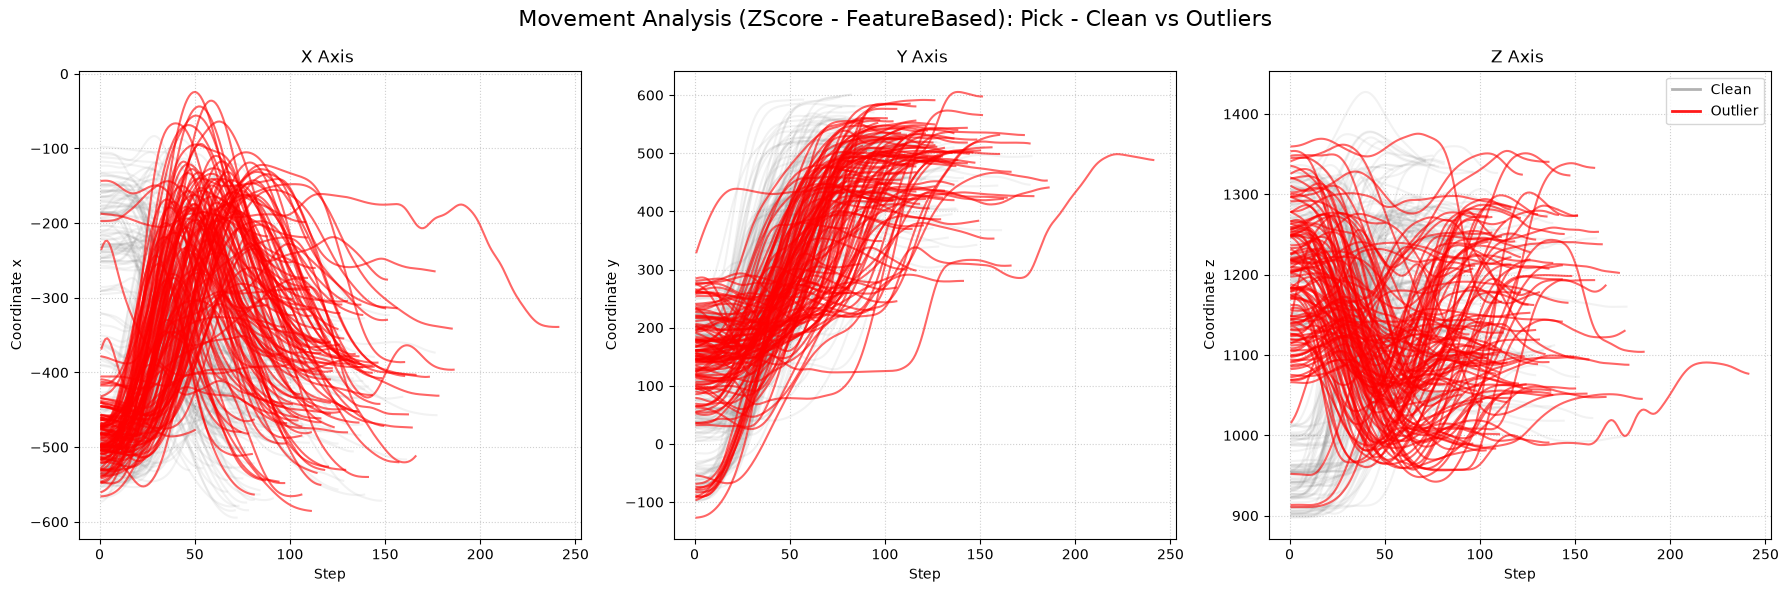

In [33]:
plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

In [34]:
# Limpeza: remover coluna auxiliar
df.drop(columns=['temp_key'], inplace=True)